# Machine Learning Operations (MLOps) — Model Experimentation & Tracking

**Nama:** Nayla Shafira Roza

**NIM:** 123450017

## Tujuan
Membangun alur eksperimen end-to-end: baseline CNN, pencatatan parameter dan metrik per epoch, minimal 20 trial tuning, evaluasi konfigurasi terbaik dengan 3 seed, ablation study, registrasi model, prediksi dari model registry, serta versioning dataset dengan DVC dan pencatatan hash.

---



---




## Setup — MLflow Tracking Server lokal (SQLite + artifact folder)


In [1]:
%pip -q install "mlflow>=2.9" optuna dvc torch torchvision scikit-learn pandas matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.1/470.1 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.3/79.3 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 451.2/451.2 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4

In [2]:
import os, json, time, random, hashlib, subprocess, sys, shutil, warnings, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import mlflow
from mlflow import MlflowClient
import optuna
warnings.filterwarnings("ignore")

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = Path(".").resolve()
DATA_DIR = ROOT / "data"
ARTIFACT_DIR = ROOT / "mlartifacts"
DATA_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
print("Device:", DEVICE, "| PyTorch:", torch.__version__, "| MLflow:", mlflow.__version__)

# Jalankan tracking server lokal dengan backend SQLite dan artifact folder.
# Jika port 5000 sudah dipakai oleh MLflow, gunakan server yang sudah aktif.
MLFLOW_DB = ROOT / "mlflow.db"
TRACKING_URI = "http://127.0.0.1:5000"
server_process = None
try:
    urllib.request.urlopen(TRACKING_URI, timeout=2).read(50)
    print("MLflow server sudah berjalan di", TRACKING_URI)
except Exception:
    cmd = [sys.executable, "-m", "mlflow", "server",
           "--backend-store-uri", f"sqlite:///{MLFLOW_DB}",
           "--default-artifact-root", ARTIFACT_DIR.as_uri(),
           "--host", "127.0.0.1", "--port", "5000"]
    server_process = subprocess.Popen(cmd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                                      cwd=str(ROOT), start_new_session=True)
    ready = False
    for _ in range(40):
        try:
            urllib.request.urlopen(TRACKING_URI, timeout=2).read(50)
            ready = True
            break
        except Exception:
            time.sleep(1)
    if not ready:
        raise RuntimeError("MLflow server gagal aktif. Periksa instalasi MLflow atau apakah port 5000 sedang digunakan.")

mlflow.set_tracking_uri(TRACKING_URI)
EXPERIMENT = "fashion-mnist-cnn-mlops"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=ARTIFACT_DIR.as_uri())
mlflow.set_experiment(EXPERIMENT)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Backend:", MLFLOW_DB)
print("Artifact folder:", ARTIFACT_DIR)
try:
    from google.colab.output import eval_js
    print("MLflow UI (buka link ini untuk screenshot):", eval_js("google.colab.kernel.proxyPort(5000)"))
except Exception:
    print("MLflow UI lokal: http://127.0.0.1:5000")


Device: cuda | PyTorch: 2.11.0+cu130 | MLflow: 3.17.0
Tracking URI: http://127.0.0.1:5000
Backend: /content/mlflow.db
Artifact folder: /content/mlartifacts
MLflow UI (buka link ini untuk screenshot): https://5000-gpu-t4-s-kkb-usw4b2-236guepsfdshv-b.us-west4-2.prod.colab.dev


## L1 — Dataset, split tetap, hash, dan versioning dengan DVC


In [5]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Fashion-MNIST: 60.000 train + 10.000 test. Transformasi dinyatakan eksplisit.
transform = transforms.ToTensor()
train_full = datasets.FashionMNIST(root="data/raw", train=True, download=True, transform=transform)
test_full  = datasets.FashionMNIST(root="data/raw", train=False, download=True, transform=transform)

# Subset tetap agar eksperimen praktikum masih realistis waktunya.
# Stratifikasi sederhana berdasarkan urutan indeks per kelas dari dataset Fashion-MNIST.
set_seed(SEED)
targets = np.array(train_full.targets)
train_idx, val_idx = [], []
for cls in range(10):
    idx = np.where(targets == cls)[0]
    rng = np.random.default_rng(SEED + cls)
    rng.shuffle(idx)
    train_idx.extend(idx[:1200].tolist())  # 12.000 data train
    val_idx.extend(idx[1200:1400].tolist()) # 2.000 data validation
test_targets = np.array(test_full.targets)
test_idx = []
for cls in range(10):
    idx = np.where(test_targets == cls)[0]
    test_idx.extend(idx[:200].tolist()) # 2.000 data test
train_ds = Subset(train_full, train_idx)
val_ds = Subset(train_full, val_idx)
test_ds = Subset(test_full, test_idx)

# Simpan snapshot data subset (tensor + label) untuk diberi hash dan versioning DVC.
def subset_to_arrays(dataset, indices):
    x = torch.stack([dataset[i][0] for i in indices]).numpy()
    y = np.array([dataset[i][1] for i in indices], dtype=np.int64)
    return x, y
Xtr, ytr = subset_to_arrays(train_full, train_idx)
Xva, yva = subset_to_arrays(train_full, val_idx)
Xte, yte = subset_to_arrays(test_full, test_idx)
snapshot = DATA_DIR / "fashion_mnist_subset.npz"
np.savez_compressed(snapshot, X_train=Xtr, y_train=ytr, X_val=Xva, y_val=yva, X_test=Xte, y_test=yte)
# Hash isi array secara kanonis agar nilainya stabil untuk data identik, tidak terpengaruh timestamp file NPZ.
hasher = hashlib.sha256()
for array_name, array in [("X_train", Xtr), ("y_train", ytr), ("X_val", Xva), ("y_val", yva), ("X_test", Xte), ("y_test", yte)]:
    contiguous = np.ascontiguousarray(array)
    hasher.update(array_name.encode("utf-8"))
    hasher.update(str(contiguous.shape).encode("utf-8"))
    hasher.update(contiguous.dtype.str.encode("utf-8"))
    hasher.update(contiguous.tobytes())
data_sha256 = hasher.hexdigest()
snapshot_file_sha256 = hashlib.sha256(snapshot.read_bytes()).hexdigest()
print("Train/val/test:", len(train_ds), len(val_ds), len(test_ds))
print("Dataset content SHA256:", data_sha256)
print("Snapshot file SHA256:", snapshot_file_sha256)

# DVC: membuat file .dvc berisi metadata/hash dataset.
# Di repository Git gunakan `dvc init`; di folder Colab tanpa Git gunakan `--no-scm`.
if not (ROOT / ".dvc").exists():
    init_cmd = ["dvc", "init"] if (ROOT / ".git").exists() else ["dvc", "init", "--no-scm"]
    dvc_init = subprocess.run(init_cmd, capture_output=True, text=True)
    if dvc_init.returncode != 0 and not (ROOT / ".dvc").exists():
        print("DVC init output:", (dvc_init.stdout + dvc_init.stderr)[-1000:])
dvc_add = subprocess.run(["dvc", "add", str(snapshot)], capture_output=True, text=True)
if dvc_add.returncode != 0:
    print("DVC add belum berhasil:", (dvc_add.stdout + dvc_add.stderr)[-1500:])
    print("Pastikan paket dvc terpasang dan folder kerja dapat ditulis, lalu jalankan ulang cell ini.")
else:
    print("DVC metadata file:", str(snapshot) + ".dvc")
    print((dvc_add.stdout or dvc_add.stderr)[-1000:])

Train/val/test: 12000 2000 2000
Dataset content SHA256: dfd40e17974b94d009421d59c178de40afd9a0b27e0ba60072a3485a510000d9
Snapshot file SHA256: 3f3cbca389b3495638a768ee1688e9657018f6b15c1bdff10401f3a3739d20f5
DVC metadata file: /content/data/fashion_mnist_subset.npz.dvc



## L2–L3 — Baseline CNN, desain eksperimen, dan tracking metrik per epoch


In [12]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.25, channels=16):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(channels, channels*2, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels*2*7*7, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 10)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def make_loaders(batch_size=128, augment=False, seed=SEED):
    if augment:
        train_transform = transforms.Compose([transforms.RandomHorizontalFlip(p=0.5), transforms.ToTensor()])
        train_data = datasets.FashionMNIST(root="data/raw", train=True, download=True, transform=train_transform)
        train_sub = Subset(train_data, train_idx)
    else:
        train_sub = train_ds
    generator = torch.Generator().manual_seed(seed)
    return (
        DataLoader(train_sub, batch_size=batch_size, shuffle=True, generator=generator, num_workers=2, pin_memory=torch.cuda.is_available()),
        DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2),
        DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)
    )

def evaluate(model, loader):
    model.eval(); losses=[]; yt=[]; yp=[]
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            logits=model(x); losses.append(criterion(logits,y).item())
            yt.extend(y.cpu().numpy()); yp.extend(logits.argmax(1).cpu().numpy())
    return float(np.mean(losses)), float(accuracy_score(yt,yp)), float(f1_score(yt,yp,average="macro")), np.array(yt), np.array(yp)

def train_model(params, seed=SEED, epochs=3, augment=False, run_name="run", log_mlflow=True):
    set_seed(seed)
    train_loader, val_loader, _ = make_loaders(int(params["batch_size"]), augment=augment, seed=seed)

    model = SmallCNN(dropout=params["dropout"], channels=int(params["channels"])).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    criterion = nn.CrossEntropyLoss()

    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_f1_macro": []}
    best_f1 = 0.0

    active_run = None
    if log_mlflow:
        active_run = mlflow.start_run(run_name=run_name, nested=True if mlflow.active_run() else False)
        mlflow.log_params(params)
        mlflow.log_param("seed", seed)
        mlflow.log_param("epochs", epochs)
        mlflow.log_param("augment", augment)

    try:
        for epoch in range(1, epochs + 1):
            model.train()
            train_losses = []
            for x, y in train_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                optimizer.zero_grad()
                loss = criterion(model(x), y)
                loss.backward()
                optimizer.step()
                train_losses.append(loss.item())

            val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader)
            train_loss_mean = float(np.mean(train_losses))

            history["epoch"].append(epoch)
            history["train_loss"].append(train_loss_mean)
            history["val_loss"].append(val_loss)
            history["val_f1_macro"].append(val_f1)

            if val_f1 > best_f1:
                best_f1 = val_f1

            if log_mlflow:
                mlflow.log_metric("train_loss", train_loss_mean, step=epoch)
                mlflow.log_metric("val_loss", val_loss, step=epoch)
                mlflow.log_metric("val_f1_macro", val_f1, step=epoch)

        if log_mlflow:
            mlflow.log_metric("best_val_f1_macro", best_f1)
            mlflow.log_dict({"history": history, "data_sha256": data_sha256}, "training_history.json")
            dummy_input = torch.randn(1, 1, 28, 28).to(DEVICE)
            # Gunakan serialization_format='pickle' untuk menghindari batasan tracing format 'pt2' di MLflow 3.x
            mlflow.pytorch.log_model(model, artifact_path="model", input_example=dummy_input, serialization_format="pickle")

        return model, pd.DataFrame(history), best_f1
    finally:
        if log_mlflow and active_run:
            mlflow.end_run()

### Baseline CNN


In [13]:
baseline_params={"lr":1e-3,"batch_size":128,"dropout":0.25,"channels":16,"weight_decay":1e-4}
baseline_model, baseline_history, baseline_f1 = train_model(
    baseline_params, seed=SEED, epochs=3, augment=False, run_name="baseline-cnn"
)
display(baseline_history)
baseline_history.to_csv("baseline_history.csv",index=False)


2026/10/10 21:57:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 21:57:53 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 21:57:54 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/10 21:58:04 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

🏃 View run baseline-cnn at: http://127.0.0.1:5000/#/experiments/1/runs/5762d9dbb9d54225afa4461e46016422
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,epoch,train_loss,val_loss,val_f1_macro
0,1,1.179133,0.644334,0.737329
1,2,0.656629,0.538091,0.782270
2,3,0.563183,0.468596,0.824796


## L4 — Hyperparameter tuning dengan Optuna (20 trial, nested runs)


In [14]:
# 20 trials minimum sesuai instruksi. Untuk mempercepat pencarian, tiap trial memakai 2 epoch.
# Parent run mengelompokkan semua child runs; metric optimasi = validation macro-F1.
def objective(trial):
    params={
        "lr":trial.suggest_float("lr",1e-4,3e-3,log=True),
        "batch_size":trial.suggest_categorical("batch_size",[64,128]),
        "dropout":trial.suggest_float("dropout",0.1,0.5),
        "channels":trial.suggest_categorical("channels",[16,32]),
        "weight_decay":trial.suggest_float("weight_decay",1e-6,1e-3,log=True)
    }
    with mlflow.start_run(run_name=f"trial-{trial.number:02d}",nested=True):
        mlflow.log_params(params)
        mlflow.set_tags({"stage":"hyperparameter_tuning","data_sha256":data_sha256})
        model,hist,best_f1=train_model(params,seed=SEED,epochs=2,augment=False,
                                       run_name=f"trial-training-{trial.number:02d}",log_mlflow=False)
        mlflow.log_metric("best_val_f1_macro",best_f1)
        mlflow.log_dict(hist.to_dict(orient="records"),"history.json")
    return best_f1

with mlflow.start_run(run_name="optuna-sweep-20"):
    mlflow.set_tags({"stage":"hyperparameter_sweep", "data_sha256":data_sha256,
                     "snapshot_file_sha256":snapshot_file_sha256})
    mlflow.log_params({"data_sha256":data_sha256,"snapshot_file_sha256":snapshot_file_sha256,
                       "n_trials_requested":20})
    study=optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective,n_trials=20,show_progress_bar=True)
    best_params=study.best_params
    mlflow.log_params({f"best_{k}":v for k,v in best_params.items()})
    mlflow.log_metric("best_val_f1_macro",study.best_value)
    mlflow.log_dict({"best_params":best_params,"best_value":study.best_value,
                     "trials":len(study.trials)},"optuna_summary.json")
print("Best validation macro-F1:",study.best_value)
print("Best parameters:",best_params)
trial_df=study.trials_dataframe()
trial_df.to_csv("optuna_trials.csv",index=False)
display(trial_df.sort_values("value",ascending=False).head())


[I 2026-10-10 21:58:48,343] A new study created in memory with name: no-name-909ce875-f6df-4393-91fa-f6d3f4b66d96


  0%|          | 0/20 [00:00<?, ?it/s]

🏃 View run trial-00 at: http://127.0.0.1:5000/#/experiments/1/runs/5201c92f0dda4478a5d9d1b9d1dda1c9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[I 2026-10-10 21:58:53,061] Trial 0 finished with value: 0.7698584643328871 and parameters: {'lr': 0.0003574712922600243, 'batch_size': 64, 'dropout': 0.3394633936788146, 'channels': 16, 'weight_decay': 1.493656855461763e-06}. Best is trial 0 with value: 0.7698584643328871.
🏃 View run trial-01 at: http://127.0.0.1:5000/#/experiments/1/runs/4b2de2cec1b1487f9676904bb0e2d606
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[I 2026-10-10 21:58:59,289] Trial 1 finished with value: 0.8248955959015578 and parameters: {'lr': 0.00190303683817358, 'batch_size': 128, 'dropout': 0.10823379771832098, 'channels': 16, 'weight_decay': 4.335281794951567e-06}. Best is trial 1 with value: 0.8248955959015578.
🏃 View run trial-02 at: http://127.0.0.1:5000/#/experiments/1/runs/74821089cc27411796993d28726bd7b4
🧪 View experiment at: http://1

,number,value,datetime_start,datetime_complete,duration,params_batch_size,params_channels,params_dropout,params_lr,params_weight_decay,system_attrs_tpe:relative_params:0,state
16,16,0.850015,2026-10-10 22:00:02.229159,2026-10-10 22:00:06.549502,0 days 00:00:04.320343,64,16,0.303709,0.002698,0.000002,"{""batch_size"": 64, ""channels"": 16, ""dropout"": ...",COMPLETE
17,17,0.839545,2026-10-10 22:00:06.553059,2026-10-10 22:00:10.959795,0 days 00:00:04.406736,64,16,0.233694,0.001707,0.000004,"{""batch_size"": 64, ""channels"": 16, ""dropout"": ...",COMPLETE
19,19,0.836752,2026-10-10 22:00:16.571176,2026-10-10 22:00:20.882260,0 days 00:00:04.311084,64,16,0.235478,0.001668,0.000001,"{""batch_size"": 64, ""channels"": 16, ""dropout"": ...",COMPLETE
14,14,0.831710,2026-10-10 21:59:53.646904,2026-10-10 21:59:57.304414,0 days 00:00:03.657510,128,16,0.229335,0.002895,0.000007,"{""batch_size"": 128, ""channels"": 16, ""dropout"":...",COMPLETE
18,18,0.829824,2026-10-10 22:00:10.962797,2026-10-10 22:00:16.568238,0 days 00:00:05.605441,64,16,0.313885,0.001075,0.000004,"{""batch_size"": 64, ""channels"": 16, ""dropout"": ...",COMPLETE


## Reproducibility: 3 seed dan laporan mean ± std


In [15]:
# Gunakan tiga seed berbeda dan laporkan mean ± standar deviasi.
seed_results=[]
for seed in [17,42,101]:
    model,hist,best_f1=train_model(best_params,seed=seed,epochs=4,augment=False,
                                  run_name=f"best-config-seed-{seed}")
    seed_results.append({"seed":seed,"best_val_f1_macro":best_f1})
seed_df=pd.DataFrame(seed_results)
seed_df.to_csv("three_seed_results.csv",index=False)
mean_f1=seed_df["best_val_f1_macro"].mean()
std_f1=seed_df["best_val_f1_macro"].std(ddof=1)
print(f"Validation macro-F1 (3 seed): {mean_f1:.4f} ± {std_f1:.4f}")
display(seed_df)


2026/10/10 22:00:35 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 22:00:36 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 22:00:36 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/10 22:00:41 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

🏃 View run best-config-seed-17 at: http://127.0.0.1:5000/#/experiments/1/runs/1642dad14dd34575a96c91de674bb20e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/10/10 22:00:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 22:00:51 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 22:00:51 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/10 22:00:56 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

🏃 View run best-config-seed-42 at: http://127.0.0.1:5000/#/experiments/1/runs/e84a6aef22e44a02a64c2d92f8d3fce2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/10/10 22:01:06 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 22:01:06 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 22:01:06 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/10 22:01:11 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

🏃 View run best-config-seed-101 at: http://127.0.0.1:5000/#/experiments/1/runs/c4d3c09c593b4e0c8261cc533cc668d0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Validation macro-F1 (3 seed): 0.8695 ± 0.0037


,seed,best_val_f1_macro
0,17,0.872842
1,42,0.865567
2,101,0.870123


## Ablation study (augmentasi dan dropout)


In [16]:
# Kontrol: konfigurasi terbaik. Ablation mengubah satu komponen per eksperimen.
ablation_results=[]
ablation_specs=[
    ("ablation-full", True, float(best_params["dropout"])),
    ("ablation-no-augmentation", False, float(best_params["dropout"])),
    ("ablation-no-dropout", True, 0.0),
]
for name,aug,drop in ablation_specs:
    p={**best_params,"dropout":drop}
    model,hist,f1v=train_model(p,seed=42,epochs=4,augment=aug,run_name=name)
    ablation_results.append({"experiment":name,"augmentation":aug,"dropout":drop,"best_val_f1_macro":f1v})
ablation_df=pd.DataFrame(ablation_results)
ablation_df.to_csv("ablation_results.csv",index=False)
display(ablation_df)


2026/10/10 22:01:27 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 22:01:27 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 22:01:27 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/10 22:01:32 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

🏃 View run ablation-full at: http://127.0.0.1:5000/#/experiments/1/runs/3ce7a530cf7643d3bc71177f808ee1db
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/10/10 22:01:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 22:01:41 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 22:01:42 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/10 22:01:47 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

🏃 View run ablation-no-augmentation at: http://127.0.0.1:5000/#/experiments/1/runs/75b3920e415c45e892cf6ad80dad02bb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/10/10 22:01:59 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 22:01:59 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 22:01:59 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/10 22:02:03 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

🏃 View run ablation-no-dropout at: http://127.0.0.1:5000/#/experiments/1/runs/5f4192a147fb432090a4c3ed41d5f940
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,experiment,augmentation,dropout,best_val_f1_macro
0,ablation-full,True,0.303709,0.862268
1,ablation-no-augmentation,False,0.303709,0.863515
2,ablation-no-dropout,True,0.000000,0.873331


## L5–L7 — Seleksi kandidat, evaluasi test final, dan Model Registry @champion


Selected tuned configuration: {'lr': 0.0026983168042481608, 'batch_size': 64, 'dropout': 0.3037091698828055, 'channels': 16, 'weight_decay': 1.5142407928952054e-06} | augmentation: True


2026/10/10 22:02:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 22:02:19 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 22:02:19 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/10 22:02:25 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

🏃 View run final-candidate at: http://127.0.0.1:5000/#/experiments/1/runs/f36b5ca504d846c8b0b03267542e1386
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
{'test_loss': 0.3910573981702328, 'test_accuracy': 0.8615, 'test_f1_macro': 0.8641154501719278}


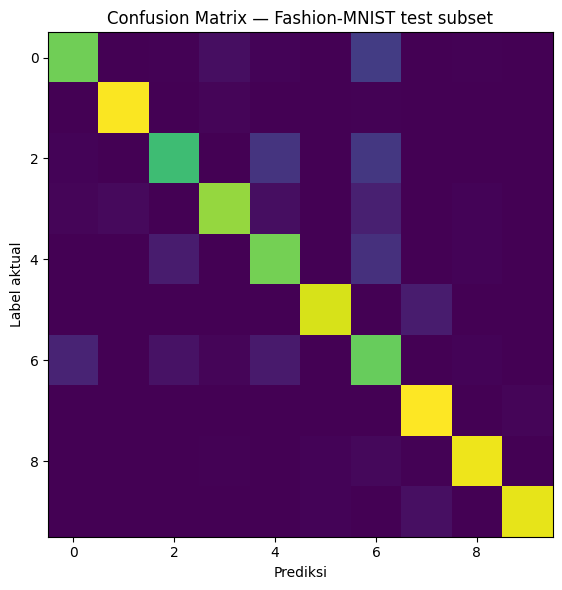

Successfully registered model 'fashion-mnist-cnn'.
2026/10/10 22:02:26 WARNING mlflow.tracking._model_registry.fluent: Run with id f36b5ca504d846c8b0b03267542e1386 has no artifacts at artifact path 'model', registering model based on models:/m-34d7de3ff09949568e972961e254938d instead


🏃 View run final-test-evaluation at: http://127.0.0.1:5000/#/experiments/1/runs/941ecad4c3ac4a9fa7228f5a9b6f7915
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/10/10 22:02:26 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: fashion-mnist-cnn, version 1
Created version '1' of model 'fashion-mnist-cnn'.


Registered: fashion-mnist-cnn version 1 alias @champion


In [17]:
# L5: Pilih kandidat berdasarkan hasil hyperparameter tuning (validation macro-F1), bukan test set.
# L6: Latih ulang konfigurasi Optuna terbaik dan evaluasi test set satu kali.
final_params = dict(best_params)
final_augment = True
print("Selected tuned configuration:", final_params, "| augmentation:", final_augment)

final_model, final_history, final_val_f1 = train_model(
    final_params, seed=42, epochs=4, augment=final_augment, run_name="final-candidate"
)
_, _, test_loader = make_loaders(int(final_params["batch_size"]), augment=False, seed=42)
test_loss, test_acc, test_f1, y_true, y_pred = evaluate(final_model, test_loader)
print({"test_loss":test_loss, "test_accuracy":test_acc, "test_f1_macro":test_f1})
with mlflow.start_run(run_name="final-test-evaluation"):
    mlflow.set_tags({"stage":"final-test", "data_sha256":data_sha256,
                     "snapshot_file_sha256":snapshot_file_sha256})
    mlflow.log_metrics({"test_loss":test_loss, "test_accuracy":test_acc, "test_f1_macro":test_f1})
    mlflow.log_text(classification_report(y_true,y_pred,target_names=[
        "T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"
    ]), "classification_report.txt")
    cm=confusion_matrix(y_true,y_pred)
    fig,ax=plt.subplots(figsize=(7,6)); ax.imshow(cm)
    ax.set_title("Confusion Matrix — Fashion-MNIST test subset")
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label aktual")
    fig.tight_layout(); fig.savefig("confusion_matrix.png",dpi=150)
    mlflow.log_artifact("confusion_matrix.png")
    plt.show()

# L7: Registrasikan model dari run final-candidate dan berikan alias @champion.
client=MlflowClient()
experiment=mlflow.get_experiment_by_name(EXPERIMENT)
runs=mlflow.search_runs(experiment_ids=[experiment.experiment_id],
                        filter_string="tags.mlflow.runName = 'final-candidate'",
                        order_by=["start_time DESC"],max_results=1)
if len(runs):
    final_run_id=runs.iloc[0]["run_id"]
    model_uri=f"runs:/{final_run_id}/model"
    model_name="fashion-mnist-cnn"
    try:
        mv=mlflow.register_model(model_uri,model_name)
        client.set_registered_model_alias(model_name,"champion",mv.version)
        client.set_model_version_tag(model_name,mv.version,"data_sha256",data_sha256)
        client.set_model_version_tag(model_name,mv.version,"validation_f1_macro",str(final_val_f1))
        print("Registered:",model_name,"version",mv.version,"alias @champion")
    except Exception as e:
        print("Registry step needs attention:",repr(e))


## L8 — Serving/prediksi melalui model registry `models:/...@champion`


In [18]:
# Prediksi via registry alias. Jika registry belum berhasil karena versi MLflow/environment,
# gunakan model URI dari run sebagai fallback untuk memeriksa prediksi.
try:
    registered_model=mlflow.pytorch.load_model("models:/fashion-mnist-cnn@champion")
    print("Model berhasil dimuat melalui alias @champion")
except Exception as e:
    print("Alias registry belum tersedia; fallback ke model final di memori.",repr(e))
    registered_model=final_model

if hasattr(registered_model, "to"):
    registered_model = registered_model.to(DEVICE)
registered_model.eval()
sample_loader=DataLoader(test_ds,batch_size=8,shuffle=False)
xb,yb=next(iter(sample_loader))
with torch.no_grad():
    preds=registered_model(xb.to(DEVICE)).argmax(1).cpu().numpy()
print("Label aktual :",yb.numpy().tolist())
print("Prediksi     :",preds.tolist())


Model berhasil dimuat melalui alias @champion
Label aktual : [0, 0, 0, 0, 0, 0, 0, 0]
Prediksi     : [0, 0, 0, 0, 0, 0, 0, 0]


## Ringkasan hasil


In [21]:
# Cari baris dengan performa terbaik di ablation study untuk mendefinisikan selected_ablation
best_idx = ablation_df["best_val_f1_macro"].idxmax()
selected_ablation = ablation_df.loc[best_idx]

summary={
 "dataset":"Fashion-MNIST subset",
 "data_sha256":data_sha256,
 "snapshot_file_sha256":snapshot_file_sha256,
 "train_size":len(train_ds),"validation_size":len(val_ds),"test_size":len(test_ds),
 "device":DEVICE,"tuning_trials":len(study.trials),
 "best_params":best_params,"best_tuning_val_macro_f1":float(study.best_value),
 "selected_final_ablation":str(selected_ablation["experiment"]),
 "final_params":final_params,"final_augmentation":final_augment,
 "final_validation_macro_f1":float(final_val_f1),
 "three_seed_mean_macro_f1":float(mean_f1),"three_seed_std_macro_f1":float(std_f1),
 "test_loss":float(test_loss),"test_accuracy":float(test_acc),"test_macro_f1":float(test_f1),
 "ablation":ablation_df.to_dict(orient="records")
}
with open("hasil_ringkasan.json","w") as f: json.dump(summary,f,indent=2)
pd.DataFrame([summary]).to_csv("hasil_ringkasan.csv",index=False)
print(json.dumps(summary,indent=2))
print("\nFile penting: mlflow.db, mlartifacts/, data/fashion_mnist_subset.npz.dvc, optuna_trials.csv, three_seed_results.csv, ablation_results.csv, hasil_ringkasan.json")

# Simpan tabel hasil sebagai artefak agar mudah diunduh dari MLflow.
with mlflow.start_run(run_name="deliverable-artifacts"):
    for artifact_file in ["optuna_trials.csv", "three_seed_results.csv", "ablation_results.csv", "hasil_ringkasan.json"]:
        if Path(artifact_file).exists():
            mlflow.log_artifact(artifact_file)
    mlflow.set_tags({"stage":"deliverables", "data_sha256":data_sha256,
                     "snapshot_file_sha256":snapshot_file_sha256})

{
  "dataset": "Fashion-MNIST subset",
  "data_sha256": "dfd40e17974b94d009421d59c178de40afd9a0b27e0ba60072a3485a510000d9",
  "snapshot_file_sha256": "3f3cbca389b3495638a768ee1688e9657018f6b15c1bdff10401f3a3739d20f5",
  "train_size": 12000,
  "validation_size": 2000,
  "test_size": 2000,
  "device": "cuda",
  "tuning_trials": 20,
  "best_params": {
    "lr": 0.0026983168042481608,
    "batch_size": 64,
    "dropout": 0.3037091698828055,
    "channels": 16,
    "weight_decay": 1.5142407928952054e-06
  },
  "best_tuning_val_macro_f1": 0.8500154942997755,
  "selected_final_ablation": "ablation-no-dropout",
  "final_params": {
    "lr": 0.0026983168042481608,
    "batch_size": 64,
    "dropout": 0.3037091698828055,
    "channels": 16,
    "weight_decay": 1.5142407928952054e-06
  },
  "final_augmentation": true,
  "final_validation_macro_f1": 0.8637460462335362,
  "three_seed_mean_macro_f1": 0.8695106324728602,
  "three_seed_std_macro_f1": 0.0036760160521139137,
  "test_loss": 0.39105739817

## Interpretasi hasil + L9 — audit lineage dan reproducibility


### L9 — Reproduce: telusuri model champion kembali ke run dan data asal
Langkah ini membaca alias `@champion`, mengambil run sumbernya, lalu menampilkan hash data, parameter, metrik, dan commit Git jika tersedia. Dengan demikian prediksi dapat ditelusuri ke asal-usul model.


In [23]:
champ = client.get_model_version_by_alias(
    "fashion-mnist-cnn", "champion"
)

client.set_model_version_tag(
    champ.name, champ.version,
    "data_sha256", data_sha256
)
client.set_model_version_tag(
    champ.name, champ.version,
    "snapshot_file_sha256", snapshot_file_sha256
)

champ = client.get_model_version(
    champ.name, champ.version
)

print({
    "model": champ.name,
    "version": champ.version,
    "alias": "@champion",
    "data_sha256": champ.tags.get("data_sha256"),
    "snapshot_file_sha256": champ.tags.get("snapshot_file_sha256")
})

{'model': 'fashion-mnist-cnn', 'version': '1', 'alias': '@champion', 'data_sha256': 'dfd40e17974b94d009421d59c178de40afd9a0b27e0ba60072a3485a510000d9', 'snapshot_file_sha256': '3f3cbca389b3495638a768ee1688e9657018f6b15c1bdff10401f3a3739d20f5'}
